# AlScN: scandium composition vs. d33 and band gap

Compares five regressors (multiple linear regression, random forest, PCR, SVR, Gaussian process) for predicting the piezoelectric coefficient d33 and the band gap of Al(1-x)Sc(x)N from composition-linked properties.

**Note:** the dataset is a compiled, smoothly varying table on a 1% Sc grid, so these scores show how well each model reproduces the compiled trend, not predictive power on new measurements.

In [1]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.metrics import mean_squared_error, r2_score
SEED = 42

In [2]:
df = pd.read_excel('../data/AlScN_Dataset.xlsx')

def parse_sci(v):
    # turns '5.000 x 10^-3' or '1.014 x 10^-6 W' into a float
    if isinstance(v, (int, float)): return float(v)
    m = re.match(r'\s*([\d.]+)\s*x\s*10\^(-?\d+)', str(v))
    return float(m.group(1)) * 10 ** int(m.group(2))

for c in ['Second Harmonic Generation', 'Dielectric Loss Tangent', 'Power Consumption PZT']:
    df[c] = df[c].map(parse_sci)
print(df.shape); df.head()

(100, 11)


,Scandium Composition,Aluminium Composition,d33,Second Harmonic Generation,Dielectric Loss Tangent,Power Consumption PZT,Coercive Field,Lattice Constant,Bond Length,Photoelasticity,Band Gap
0,1,99,30.10,0.005000,0.000405,0.000001,191.39,3.10,0.5383,0.02,6.60
1,2,98,30.28,0.005010,0.000406,0.000001,192.58,3.12,0.5377,0.04,6.56
2,3,97,30.46,0.005021,0.000408,0.000001,193.77,3.14,0.5371,0.07,6.52
3,4,96,30.64,0.005031,0.000409,0.000001,194.96,3.15,0.5369,0.10,6.48
4,5,95,30.82,0.005041,0.000411,0.000001,196.15,3.16,0.5367,0.13,6.44


['Scandium Composition', 'Second Harmonic Generation', 'Dielectric Loss Tangent', 'Power Consumption PZT', 'Coercive Field', 'Lattice Constant', 'Bond Length', 'Photoelasticity']


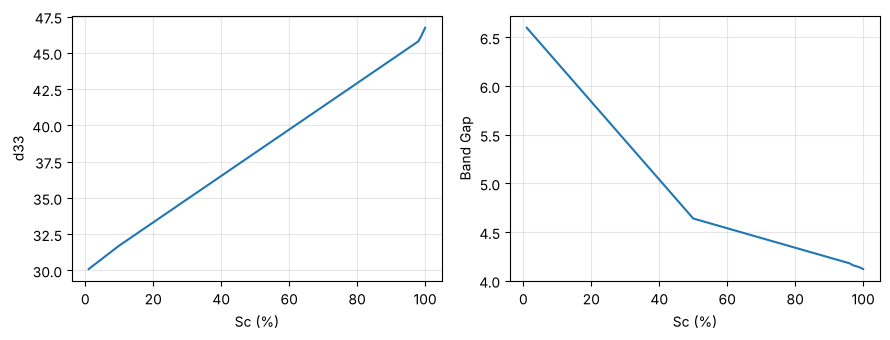

In [3]:
targets = ['d33', 'Band Gap']
all_features = [c for c in df.columns if c not in targets + ['Aluminium Composition']]
print(all_features)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for a, t in zip(ax, targets):
    a.plot(df['Scandium Composition'], df[t]); a.set_xlabel('Sc (%)'); a.set_ylabel(t); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('../figures/trends_vs_sc.png', dpi=200); plt.show()

In [4]:
def models(n_features):
    gp_kernel = ConstantKernel(1.0) * RBF(length_scale=1.0, length_scale_bounds=(0.5, 1e3)) + WhiteKernel(1e-5, noise_level_bounds=(1e-10, 1e-1))
    return {
        'MLR': make_pipeline(StandardScaler(), LinearRegression()),
        'Random Forest': RandomForestRegressor(n_estimators=300, random_state=SEED),
        'PCR': make_pipeline(StandardScaler(), PCA(n_components=min(3, n_features)), LinearRegression()),
        'SVR': make_pipeline(StandardScaler(), SVR(C=100, epsilon=0.01)),
        'GPR': make_pipeline(StandardScaler(), GaussianProcessRegressor(kernel=gp_kernel, normalize_y=True, random_state=SEED, n_restarts_optimizer=2)),
    }

def run(features, train_idx, test_idx):
    rows = {}; preds = {}
    for t in targets:
        for name, m in models(len(features)).items():
            m.fit(df.loc[train_idx, features], df.loc[train_idx, t])
            p = m.predict(df.loc[test_idx, features]); preds[(t, name)] = p
            rows[(t, name)] = {'RMSE': mean_squared_error(df.loc[test_idx, t], p) ** .5,
                               'R2': r2_score(df.loc[test_idx, t], p)}
    return pd.DataFrame(rows).T, preds

## 1. Random 80/20 split (interpolation)

In [5]:
tr, te = train_test_split(df.index, test_size=0.2, random_state=SEED)
res_random, preds_random = run(all_features, tr, te)
res_random.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 18 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


RMSE      R2
d33      MLR            0.0052  1.0000
         Random Forest  0.0913  0.9996
         PCR            0.0212  1.0000
         SVR            0.0096  1.0000
         GPR            0.0001  1.0000
Band Gap MLR            0.0036  1.0000
         Random Forest  0.0194  0.9994
         PCR            0.0052  1.0000
         SVR            0.0082  0.9999
         GPR            0.0006  1.0000

## 2. Extrapolation: train on Sc <= 70%, test on Sc > 70%

In [6]:
tr_e = df.index[df['Scandium Composition'] <= 70]; te_e = df.index[df['Scandium Composition'] > 70]
res_extrap, preds_extrap = run(all_features, tr_e, te_e)
res_extrap.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


RMSE       R2
d33      MLR            0.1120   0.9939
         Random Forest  2.9690  -3.2646
         PCR            0.0891   0.9962
         SVR            4.9645 -10.9238
         GPR            0.1121   0.9939
Band Gap MLR            0.0824   0.1469
         Random Forest  0.1852  -3.3025
         PCR            0.0149   0.9722
         SVR            0.6938 -59.4207
         GPR            0.2494  -6.8068

## 3. Sc content alone as the only input (random split)

In [7]:
res_sc, _ = run(['Scandium Composition'], tr, te)
res_sc.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.5. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.5. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


RMSE      R2
d33      MLR            0.0409  0.9999
         Random Forest  0.1105  0.9994
         PCR            0.0409  0.9999
         SVR            0.0078  1.0000
         GPR            0.0067  1.0000
Band Gap MLR            0.2007  0.9321
         Random Forest  0.0226  0.9991
         PCR            0.2007  0.9321
         SVR            0.0084  0.9999
         GPR            0.0045  1.0000

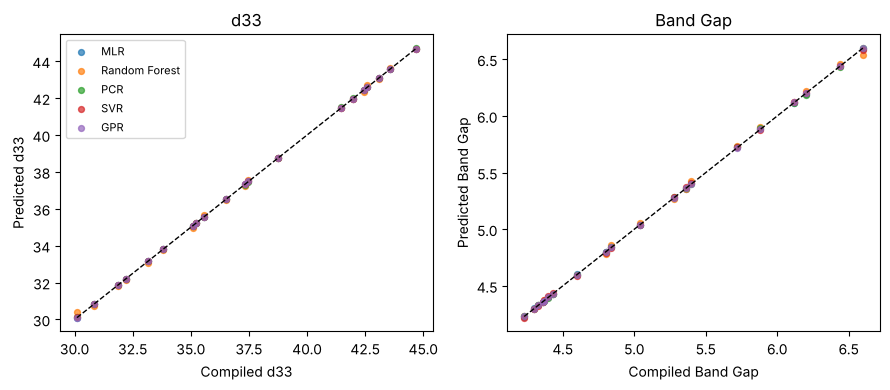

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, t in zip(ax, targets):
    y = df.loc[te, t]
    for name in models(len(all_features)):
        a.scatter(y, preds_random[(t, name)], s=18, label=name, alpha=.7)
    lo, hi = y.min(), y.max(); a.plot([lo, hi], [lo, hi], 'k--', lw=1)
    a.set_xlabel(f'Compiled {t}'); a.set_ylabel(f'Predicted {t}'); a.set_title(t)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig('../figures/parity_random_split.png', dpi=200); plt.show()

In [9]:
summary = pd.concat({'Random split': res_random, 'Extrapolation (Sc > 70%)': res_extrap, 'Sc only': res_sc})
summary.round(4).to_csv('../results_summary.csv'); summary.round(4)

RMSE       R2
Random split             d33      MLR            0.0052   1.0000
                                  Random Forest  0.0913   0.9996
                                  PCR            0.0212   1.0000
                                  SVR            0.0096   1.0000
                                  GPR            0.0001   1.0000
                         Band Gap MLR            0.0036   1.0000
                                  Random Forest  0.0194   0.9994
                                  PCR            0.0052   1.0000
                                  SVR            0.0082   0.9999
                                  GPR            0.0006   1.0000
Extrapolation (Sc > 70%) d33      MLR            0.1120   0.9939
                                  Random Forest  2.9690  -3.2646
                                  PCR            0.0891   0.9962
                                  SVR            4.9645 -10.9238
                                  GPR            0.1121   0.9939
                         Band Gap MLR            0.0824   0.1469
                                  Random Forest  0.1852  -3.3025
                                  PCR            0.0149   0.9722
                                  SVR            0.6938 -59.4207
                                  GPR            0.2494  -6.8068
Sc only                  d33      MLR            0.0409   0.9999
                                  Random Forest  0.1105   0.9994
                                  PCR            0.0409   0.9999
                                  SVR            0.0078   1.0000
                                  GPR            0.0067   1.0000
                         Band Gap MLR            0.2007   0.9321
                                  Random Forest  0.0226   0.9991
                                  PCR            0.2007   0.9321
                                  SVR            0.0084   0.9999
                                  GPR            0.0045   1.0000